In [70]:
import os
import sys
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.lines import Line2D

import project_settings
importlib.reload(project_settings)
from project_settings import PATH_WRK, RESULTS_DIR

BLOCS = ["USA", "EU27", "RestOECD", "China", "RestBRICS", "RestAsia", "RoW"]
BLOC_MARKERS = {"USA": "o", "EU27": "s", "RestOECD": "^", "China": "D", "RestBRICS": "P", "RestAsia": "X", "RoW": "v"}
SCENARIO_COLORS = {"A": "#1f77b4", "B": "#ff7f0e"}
MODEL_LABELS = {2: "model 2 (D / F)", 3: "model 3 (X / I)", 4: "model 4 (4 channels)"}
SCENARIO_LABELS = {"A": "scenario A", "B": "scenario B"}


In [71]:
def export_graph(plot, path, dpi=300):

    if isinstance(plot, tuple):
        fig = plot[0]
    elif isinstance(plot, Figure):
        fig = plot
    else:
        fig = plot.figure

    folder = os.path.dirname(path)
    if folder:
        os.makedirs(folder, exist_ok=True)

    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    return path


def load_choc(base, content, year, model, choc_files=("A", "B"), folder=None):
    folder = folder or f"{RESULTS_DIR}choc_tfp/"
    frames = []
    for s in choc_files:
        path = f"{folder}resultats{model}_blocs_{base}_{content}_{year}_choc{s}.csv"
        if not os.path.exists(path):
            print(f"[skipped] no results file: {path}")
            continue
        frames.append(pd.read_csv(path))
    if not frames:
        raise FileNotFoundError(f"no results file for {base} / {content} / {year} / model {model} in {folder}")
    return pd.concat(frames, ignore_index=True).drop_duplicates(["bloc", "sector", "scenario"])


def plot_choc(df, sectors, blocs=BLOCS, scenarios=("A", "B"), model=2, title=None, figsize=None,
              jitter=0.07, seed=0, y_min=None, y_max=None):
    rng = np.random.default_rng(seed)
    missing = [s for s in sectors if s not in set(df["sector"])]
    if missing:
        print(f"[plot_choc] sectors not in the results, left out: {missing}")
    sectors = [s for s in sectors if s not in missing]
    if y_min is not None:
        df = df[df["dlnCost"] >= y_min]
    if y_max is not None:
        df = df[df["dlnCost"] <= y_max]
    n_sc = len(scenarios)
    slot = 0.8 / n_sc
    box_width = slot * 0.8
    if title is None:
        title = "Change in unit cost (dlnCost) by sector, coalition block and scenario"
    title = f"{title}\n{MODEL_LABELS[model]}"

    fig, ax = plt.subplots(figsize=figsize or (max(8.0, 0.6 * len(sectors) * n_sc / 2 + 3), 6))
    xticks, xticklabels = [], []

    for si, sector in enumerate(sectors):
        ax.text(si, -0.1, sector, transform=ax.get_xaxis_transform(), ha="right", va="top", fontsize=10, fontweight="bold", rotation=45)
        for k, scenario in enumerate(scenarios):
            center = si + (k - (n_sc - 1) / 2) * slot
            xticks.append(center)
            xticklabels.append(scenario)
            sub = df[(df["sector"] == sector) & (df["scenario"] == scenario) & df["bloc"].isin(blocs)]
            if sub.empty:
                continue
            ax.boxplot(
                sub["dlnCost"].values, positions=[center], widths=box_width,
                showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="none", edgecolor="black", linewidth=1),
                medianprops=dict(color="black"), whiskerprops=dict(color="black"),
                capprops=dict(color="black"), zorder=2,
            )
            for bloc in blocs:
                pts = sub[sub["bloc"] == bloc]
                if pts.empty:
                    continue
                ax.scatter(center + rng.uniform(-jitter, jitter, size=len(pts)), pts["dlnCost"],
                           color=SCENARIO_COLORS[scenario], marker=BLOC_MARKERS[bloc], s=60, zorder=3,
                           edgecolors="black", linewidths=0.5, label="_nolegend_")

    ax.axhline(0, color="black", linewidth=0.7, linestyle="--", zorder=0)
    for k in range(1, len(sectors)):
        ax.axvline(k - 0.5, color="gray", linestyle=":", linewidth=0.8, alpha=0.6, zorder=0)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels, fontsize=9)
    ax.set_xlim(-0.5, len(sectors) - 0.5)
    ax.set_ylabel("dlnCost (change in log unit cost vs baseline: 0.01 = about +1 %)")
    ax.set_title(title)

    legend_handles = (
        [Line2D([0], [0], marker="s", color="none", markerfacecolor=SCENARIO_COLORS[s], markeredgecolor="black",
                markersize=9, label=SCENARIO_LABELS[s]) for s in scenarios]
        + [Line2D([0], [0], marker=BLOC_MARKERS[b], color="none", markerfacecolor="white", markeredgecolor="black",
                  markersize=9, label=b) for b in blocs]
    )
    ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=5)
    fig.tight_layout()
    return fig, ax


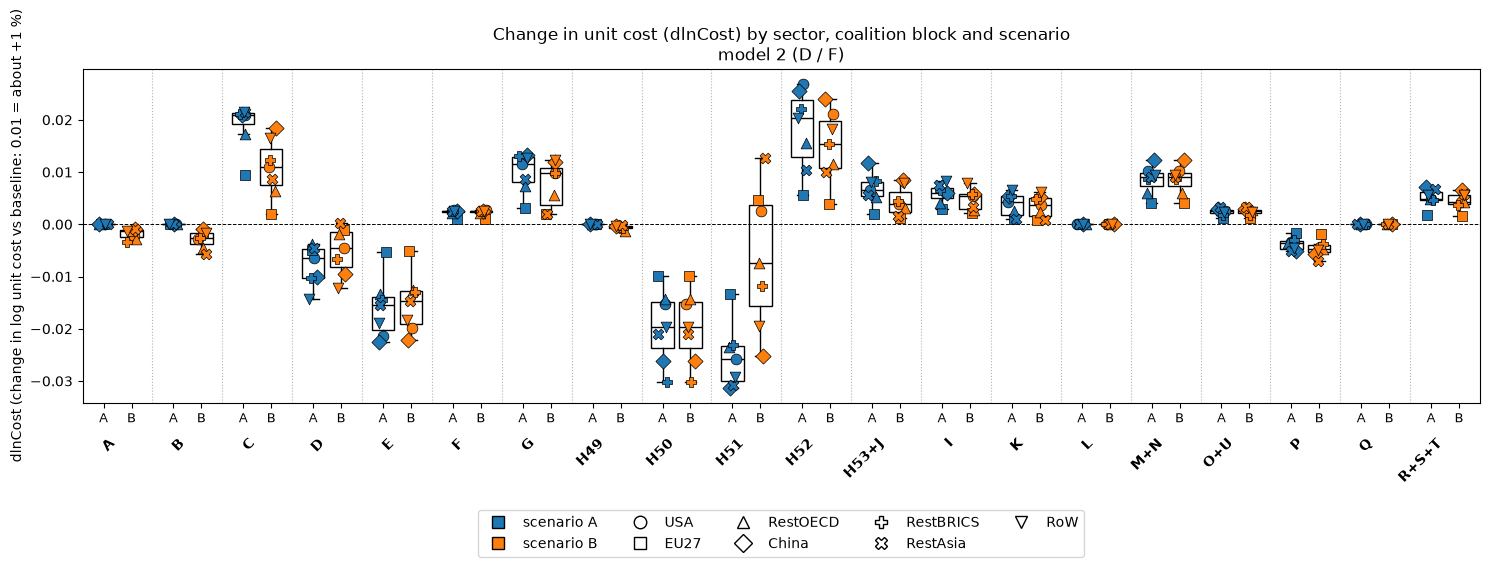

In [72]:
BASE = "GTAP"
CONTENT = "dir"             # "dir" : rd_dir_CI | "tot" : rd_tot_CI
YEAR = 2022
MODEL = 2                   # 2,3 ou 4
CHOC_FILES = ["B"]
SCENARIOS = ["A", "B"]


# "A", "B", "C", "C10_C12", "C13_C15", "C16_C18", "C19", "C20+C21", "C22", "C23", "C24", "C25", "C26", "C27", "C28", "C29", "C30", "C31_C33", "D", "E", "F", "G", "H49", "H50", "H51", "H52", "H53+J", "I", "K", "L", "M+N", "O+U", "P", "Q", "R+S+T"
SECTORS = ["A", "B", "C", "D", "E", "F", "G", "H49", "H50", "H51", "H52", "H53+J", "I", "K", "L", "M+N", "O+U", "P", "Q", "R+S+T"]
BLOCS_TO_PLOT = BLOCS      # ou une sélection, par exemple ["USA", "EU27", "China"]

df_choc = load_choc(BASE, CONTENT, YEAR, MODEL, CHOC_FILES)
fig, ax = plot_choc(df_choc, SECTORS, BLOCS_TO_PLOT, SCENARIOS, MODEL)
export_graph((fig, ax), RESULTS_DIR + f"graphs/choc_dlnCost_{BASE}_{CONTENT}_{YEAR}_modele{MODEL}.png")
plt.show()
